In [76]:
#double pendulum

#d^2theta1 / dt^2 = (m2 g sin(theta2) cos(theta1- theta2) - m2 sin(theta1 - theta2) (L1 (dtheta1 / dt)^2 cos(theta1 - theta2) + L2 (dtheta2 / dt)^2 - (m1 + m2) g sin(theta1)) / (L1 (m1 + m2 sin^2(theta1 - theta2)))
#d^2theta2 / dt^2 = ((m1 + m2) (L1 (dtheta1 / dt)^2 sin(theta1 - theta2) - g sin(theta2) + g sin(theta1) cos(theta1 - theta2)) + m2 L2 (dtheta2 / dt)^2 sin(theta1 - theta2) cos(theta1 - theta2) / (L2 (m1 + m2 sin^2(theta1 - theta2)))

import numpy as np
import matplotlib.pyplot as plt

#set data
m1 = 1
m2 = 1
L1 = 1
L2 = 1

def f(theta1, theta2, v1, v2):
    return v1, (m2 * 9.8 * np.sin(theta2) * np.cos(theta1 - theta2) - m2 * np.sin(theta1 - theta2) * (L1 * v1**2 * np.cos(theta1 - theta2) + L2 * v2**2) - (m1 + m2) * 9.8 * np.sin(theta1)) / (L1 * (m1 + m2 * (np.sin(theta1 - theta2))**2))

def g(theta1, theta2, v1, v2):
    return v2, ((m1 + m2) * (L1 * v1**2 * np.sin(theta1 - theta2) - 9.8 * np.sin(theta2) + 9.8 * np.sin(theta1) * np.cos(theta1 - theta2)) + m2 * L2 * v2**2 * np.sin(theta1 - theta2) * np.cos(theta1 - theta2)) / (L2 * (m1 + m2 * (np.sin(theta1 - theta2))**2))
        

In [96]:
#using rk4 method

t = 0
tmax = 10

#set time-step
h = 0.01

#set initial conditions
theta1 = 0.2
v1 = 0

theta2 = 0
v2 = 0

time = [t]
displacement1 = [theta1]
velocity1 = [v1]

displacement2 = [theta2]
velocity2 = [v2]

while t < tmax - 1e-12:
    k1theta1, k1v1 = f(theta1, theta2, v1, v2)
    k1theta2, k1v2 = g(theta1, theta2, v1, v2)
    
    k2theta1, k2v1 = f(theta1 + h/2*k1theta1, theta2 + h/2*k1theta2, v1 + h/2*k1v1, v2 + h/2*k1v2)
    k2theta2, k2v2 = g(theta1 + h/2*k1theta1, theta2 + h/2*k1theta2, v1 + h/2*k1v1, v2 + h/2*k1v2)
    
    k3theta1, k3v1 = f(theta1 + h/2*k2theta1, theta2 + h/2*k2theta2, v1 + h/2*k2v1, v2 + h/2*k2v2)
    k3theta2, k3v2 = g(theta1 + h/2*k2theta1, theta2 + h/2*k2theta2, v1 + h/2*k2v1, v2 + h/2*k2v2)
    
    k4theta1, k4v1 = f(theta1 + h*k3theta1, theta2 + h*k3theta2, v1 + h*k3v1, v2 + h*k3v2)
    k4theta2, k4v2 = g(theta1 + h*k3theta1, theta2 + h*k3theta2, v1 + h*k3v1, v2 + h*k3v2)
    
    v1 = v1 + h * (k1v1 + 2 * k2v1 + 2 * k3v1 + k4v1) / 6  
    theta1 = theta1 + h * (k1theta1 + 2 * k2theta1 + 2 * k3theta1 + k4theta1) / 6

    v2 = v2 + h * (k1v2 + 2 * k2v2 + 2 * k3v2 + k4v2) / 6  
    theta2 = theta2 + h * (k1theta2 + 2 * k2theta2 + 2 * k3theta2 + k4theta2) / 6
    
    t = t + h

    time.append(t)
    displacement1.append(theta1)
    velocity1.append(v1)
    displacement2.append(theta2)
    velocity2.append(v2)

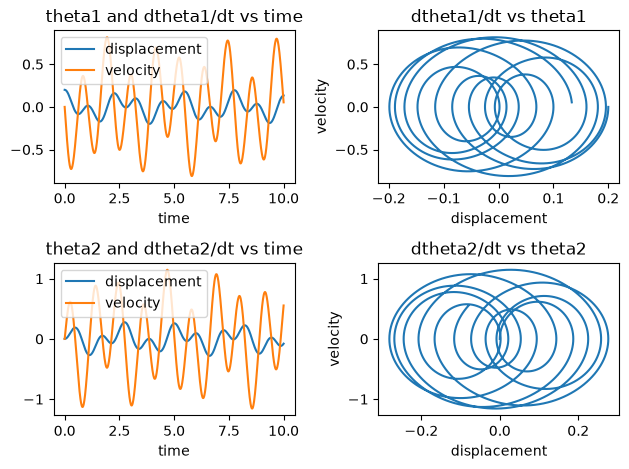

In [97]:
#plots

fig, ax = plt.subplots(2, 2)

ax[0, 0].plot(time, displacement1)
ax[0, 0].plot(time, velocity1)
ax[0, 0].set_title("theta1 and dtheta1/dt vs time")
ax[0, 0].set_xlabel("time")
ax[0, 0].legend(["displacement", "velocity"])

ax[0, 1].plot(displacement1, velocity1)
ax[0, 1].set_title("dtheta1/dt vs theta1")
ax[0, 1].set_xlabel("displacement")
ax[0, 1].set_ylabel("velocity")

ax[1, 0].plot(time, displacement2)
ax[1, 0].plot(time, velocity2)
ax[1, 0].set_title("theta2 and dtheta2/dt vs time")
ax[1, 0].set_xlabel("time")
ax[1, 0].legend(["displacement", "velocity"])

ax[1, 1].plot(displacement2, velocity2)
ax[1, 1].set_title("dtheta2/dt vs theta2")
ax[1, 1].set_xlabel("displacement")
ax[1, 1].set_ylabel("velocity")
plt.tight_layout()
plt.show()